# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. Here we render them as deliverables and evaluate **Gate 2**, on the
non-cycling developmental compartment the trajectory was scoped to in 02.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into
*distinct arms* with Crest terminal. A non-branching manifold instead shows a **shared
developmental gradient**: Gast and pSom co-vary along the trajectory body while Crest occupies
the opposite (terminal) end as an inverse gradient. That pattern **is present** in the scoped
Filbin 2018 manifold — smoothed Gast↔pSom strongly positive (co-vary), Crest inversely
correlated with both and rising to a terminal neural-crest pole along pseudotime (exact values
printed below) — so **Gate 2 = GO**; with no Gast↔pSom bifurcation, Gate 3 = NA.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print('%s: %d/%d genes present | mean score %+.3f' % (lab, g.size, feat[src].size, adata.obs[lab].mean()))

cells: 1746 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 78/81 genes present | mean score +0.019
pSom: 93/98 genes present | mean score +0.205
Crest: 102/104 genes present | mean score +0.116


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: (i) Gast & pSom co-vary spatially (positive
smoothed correlation, no divergent arms); (ii) Crest is anti-correlated with both; (iii) along
pseudotime Gast declines while Crest rises to a terminal pole. The Crest-high decile falls at
late pseudotime, confirming Crest is the terminal readout.

In [ ]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    print('  %-9s vs %-9s: r = %+.2f' % (a, b, np.corrcoef(adata.obs[a], adata.obs[b])[0,1]))
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    print('  %-9s: rho = %+.3f' % (s, spearmanr(t, adata.obs[s])[0]))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Neural-crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())
r_gp = np.corrcoef(adata.obs['Gast_sm'], adata.obs['pSom_sm'])[0,1]
rho_cr = spearmanr(adata.obs['t'].values, adata.obs['Crest_sm'])[0]
print('Gast<->pSom co-vary (r=%+.2f); Crest inverse terminal pole (rising rho=%+.2f).' % (r_gp, rho_cr))
print('Gate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no Gast<->pSom bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm   vs pSom_sm  : r = +0.79
  Crest_sm  vs Gast_sm  : r = -0.89
  Crest_sm  vs pSom_sm  : r = -0.57
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm  : rho = -0.687
  pSom_sm  : rho = -0.296
  Crest_sm : rho = +0.909
Neural-crest-high decile mean pseudotime = 1.00 (terminal if ~1)
Gast<->pSom co-vary (r=+0.79); Crest inverse terminal pole (rising rho=+0.91).
Gate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)
Gate 3: no Gast<->pSom bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right (`X_umap_lin`), `size=30`, plasma,
**raw** (not smoothed) score per cell so SmartSeq2 dropout is visible (smoothing is used only
for the analysis reads above, never for the deliverable panels). Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


<ipython-input-5-508a723aa1bd>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-5-508a723aa1bd>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-5-508a723aa1bd>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)


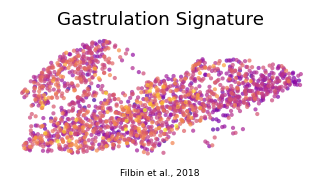

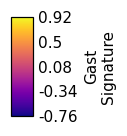

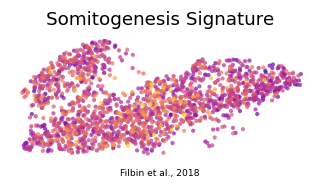

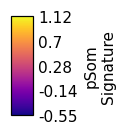

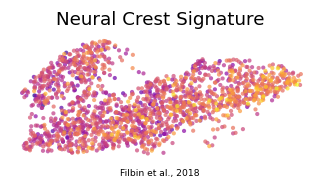

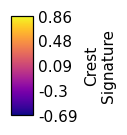

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature', 'pSom':'Somitogenesis Signature', 'Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, m + '_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(m + '\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, m + '_colorbar.pdf'), bbox_inches='tight')
    print('saved', m + '_signature.pdf', '+ colorbar')

### Save signatures data

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (1746, 21106)
